# Exploratory analysis and visual quality control

Medvolt.AI — mutation-effect prediction and candidate prioritization.

This notebook is the **exploratory** counterpart to the pipeline in `src/`: it
inspects the raw data and justifies the three design decisions that the rest of
the project then enforces in code.

1. **Schema and anomalies** — what is missing, infinite or out of range?
2. **Targets** — how are `stability_ddG` and `functional_score` distributed, and how
   related are they?
3. **Nesting** — mutations sit inside proteins, which sit inside families. This is
   why the project cross-validates by *family*, not at random.
4. **Embeddings** — the 256-d protein embedding is constant within a protein, which
   bounds what it can contribute to a *within-protein* mutation ranking.
5. **Candidates vs training data** — how much of the candidate pool is out of
   distribution?

Nothing here is hardcoded: paths, column names and policy all come from
`config/config.yaml` and `src/common/constants.py`, so this notebook cannot
silently drift from the pipeline it documents.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from anywhere: anchor imports at the project root (the folder holding main.py).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import data_processing as dp
from src.common import constants as const
from src.common.config import load_config

cfg = load_config(PROJECT_ROOT / "config" / "config.yaml")
rng = np.random.default_rng(cfg["project"]["random_seed"])

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

print(f"project root : {PROJECT_ROOT}")
print(f"random seed  : {cfg['project']['random_seed']}")
print(f"targets      : {list(const.TARGETS.values())}")

project root : /Users/ambujsrivastava/Documents/Drug_discovery/Medvolt_Coding_test/Protein_mutation/medvolt_protein_engineering
random seed  : 20261102
targets      : ['stability_ddG', 'functional_score']


## 1. Load and validate the raw tables

`src.data_processing` owns ingestion, so the notebook sees exactly what the pipeline
sees — including the schema validation, which raises if a required column is absent.

In [2]:
frames = dp.load_raw_data(cfg)
for name, frame in frames.items():
    print(f"{name:<12} {frame.shape[0]:>5} rows x {frame.shape[1]:>4} columns")

labeled = frames[const.TABLE_LABELED]
candidates = frames[const.TABLE_CANDIDATES]
embeddings = frames[const.TABLE_EMBEDDINGS]
labeled.head()

labeled        840 rows x   20 columns
candidates     180 rows x   18 columns
embeddings      36 rows x  259 columns


,mutation_id,protein_id,protein_family,protein_length,wt_amino_acid,position,mutant_amino_acid,conservation_score,solvent_accessibility,secondary_structure,distance_to_active_site,local_confidence_score,wt_hydrophobicity,mutant_hydrophobicity,wt_charge,mutant_charge,wt_volume,mutant_volume,stability_ddG,functional_score
0,MUT00001,PROT007,PF02,559,R,295,V,0.4078,0.3345,H,18.353,79.38,-4.5,4.2,1.00,0.0,173.4,140.0,1.1349,0.7479
1,MUT00002,PROT004,PF01,289,V,170,D,0.4127,0.5024,H,30.741,87.59,4.2,-3.5,0.00,-1.0,140.0,111.1,1.1139,0.7598
2,MUT00003,PROT026,PF07,478,H,128,I,0.4219,0.6352,C,17.429,70.59,-3.2,4.5,0.15,0.0,153.2,166.7,1.3059,0.8802
3,MUT00004,PROT023,PF06,577,E,258,D,0.4932,0.7704,C,14.416,65.67,-3.5,-3.5,-1.00,-1.0,138.4,111.1,0.1424,0.8076
4,MUT00005,PROT001,PF01,483,W,13,G,0.3098,0.5289,H,28.158,86.48,-0.9,-0.4,0.00,0.0,227.8,60.1,0.3891,0.8156


In [3]:
# Merge exactly as Phase 1 does: many mutations -> one embedding row per protein.
labeled_merged = dp.merge_embeddings(labeled, embeddings, cfg, const.TABLE_LABELED)
candidates_merged = dp.merge_embeddings(candidates, embeddings, cfg, const.TABLE_CANDIDATES)
print(f"labeled    {labeled.shape} -> {labeled_merged.shape}")
print(f"candidates {candidates.shape} -> {candidates_merged.shape}")

labeled    (840, 20) -> (840, 276)
candidates (180, 18) -> (180, 274)


## 2. Data quality: missing, infinite and out-of-range values

`inspect_anomalies` reports; `handle_anomalies` applies the policy in
`config.yaml → quality`. Looking at the report *before* the policy runs is the point
of this section — it is the evidence that the policy is the right one.

In [4]:
report = dp.inspect_anomalies(labeled_merged, const.TABLE_LABELED)
for key, value in report.items():
    if isinstance(value, dict) and not value:
        print(f"{key}: none")
    else:
        print(f"{key}: {value}")

rows: 840
missing: none
infinite: none
out_of_range: none


In [5]:
# Missingness per non-embedding column, as a share of rows.
non_embedding = [c for c in labeled_merged.columns if not c.startswith(const.EMBEDDING_PREFIX)]
missing = labeled_merged[non_embedding].isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

if missing.empty:
    print("No missing values in any non-embedding column.")
else:
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.35 * len(missing))))
    ax.barh(missing.index[::-1], missing.to_numpy()[::-1])
    ax.set_xlabel("fraction of rows missing")
    ax.set_title("Missingness by column (labeled mutations)")
    fig.tight_layout()
    plt.show()
    display(missing.to_frame("missing_fraction"))

No missing values in any non-embedding column.


## 3. The two targets

`stability_ddG` is a free-energy change in kcal/mol — **negative is stabilizing**, so
the prioritization objective is applied to `-ddG`. `functional_score` is a bounded
activity score where higher is better. Their relationship decides whether a single
combined objective would be enough, or whether the two must be traded off explicitly.

,count,mean,std,min,25%,50%,75%,max
stability_ddG,840.0,0.553826,0.524779,-1.2913,0.2191,0.51210,0.868275,2.7943
functional_score,840.0,0.745589,0.114895,0.2675,0.6824,0.75725,0.822100,1.0000


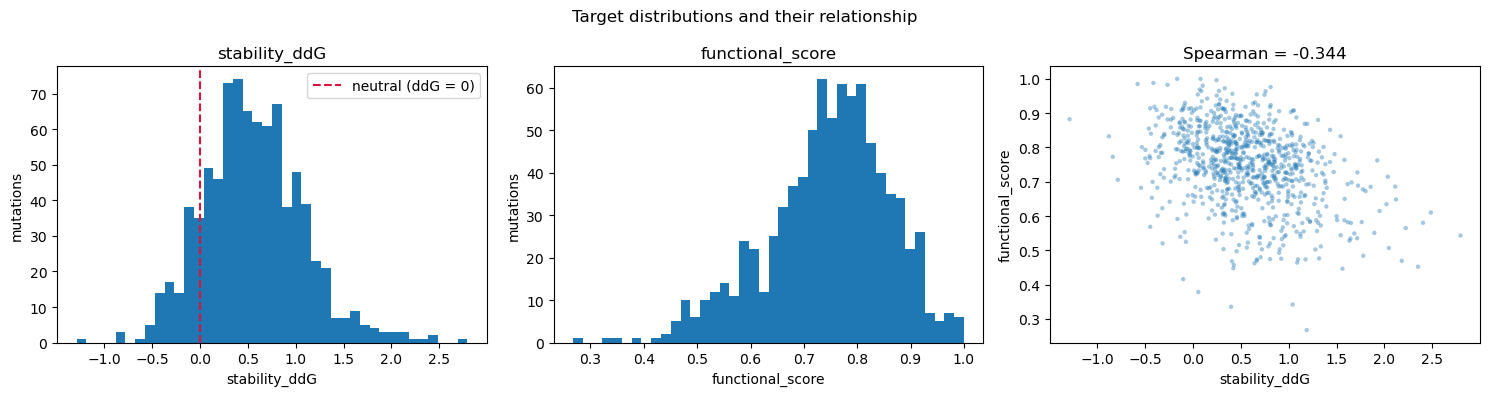

Share of labeled mutations that are stabilizing (ddG < 0): 14.0%


In [6]:
targets = list(const.TARGETS.values())
display(labeled_merged[targets].describe().T)

fig, axes = plt.subplots(1, len(targets) + 1, figsize=(5.0 * (len(targets) + 1), 4.0))
for ax, target in zip(axes[:-1], targets, strict=True):
    ax.hist(labeled_merged[target].dropna(), bins=40)
    ax.set_xlabel(target)
    ax.set_ylabel("mutations")
    ax.set_title(target)
axes[0].axvline(0.0, color="crimson", linestyle="--", label="neutral (ddG = 0)")
axes[0].legend()

axes[-1].scatter(labeled_merged[targets[0]], labeled_merged[targets[1]], s=10, alpha=0.4,
                 edgecolor="none")
axes[-1].set_xlabel(targets[0])
axes[-1].set_ylabel(targets[1])
spearman = labeled_merged[targets].corr(method="spearman").iloc[0, 1]
axes[-1].set_title(f"Spearman = {spearman:+.3f}")
fig.suptitle("Target distributions and their relationship")
fig.tight_layout()
plt.show()

stabilizing = (labeled_merged[targets[0]] < 0).mean()
print(f"Share of labeled mutations that are stabilizing (ddG < 0): {stabilizing:.1%}")

The two targets are only partly redundant, and destabilizing mutations dominate.
Both facts matter downstream: the first justifies the **two-objective** priority score
rather than one combined label, the second explains why the Top-10 is largely a ranking
of *least destabilizing* candidates rather than confidently stabilizing ones.

## 4. Nesting: mutations within proteins within families

This is the single most important structural fact in the dataset, and the reason the
pipeline's primary cross-validation is grouped by `protein_family`. If folds are drawn
at random, every protein and every family appears on both sides of every split, and the
model is rewarded for recognising proteins it has already seen.

In [7]:
nesting = (
    labeled_merged.groupby(const.COL_PROTEIN_FAMILY)
    .agg(
        n_mutations=(const.COL_MUTATION_ID, "size"),
        n_proteins=(const.COL_PROTEIN_ID, "nunique"),
        mean_ddG=(targets[0], "mean"),
        mean_function=(targets[1], "mean"),
    )
    .sort_values("n_mutations", ascending=False)
)
display(nesting)

per_protein = labeled_merged.groupby(const.COL_PROTEIN_ID).size()
print(f"{len(nesting)} families, {per_protein.size} proteins, {len(labeled_merged)} mutations")
print(f"Mutations per protein: min {per_protein.min()}, median {per_protein.median():.0f}, "
      f"max {per_protein.max()}")

,n_mutations,n_proteins,mean_ddG,mean_function
protein_family,,,,
PF01,135,4,0.504462,0.720125
PF06,130,4,0.353555,0.794368
PF07,122,4,0.735786,0.761673
PF03,120,4,0.404603,0.755219
PF05,116,4,0.802798,0.736173
PF04,111,4,0.662346,0.691395
PF02,106,4,0.435715,0.755836


7 families, 28 proteins, 840 mutations
Mutations per protein: min 19, median 31, max 41


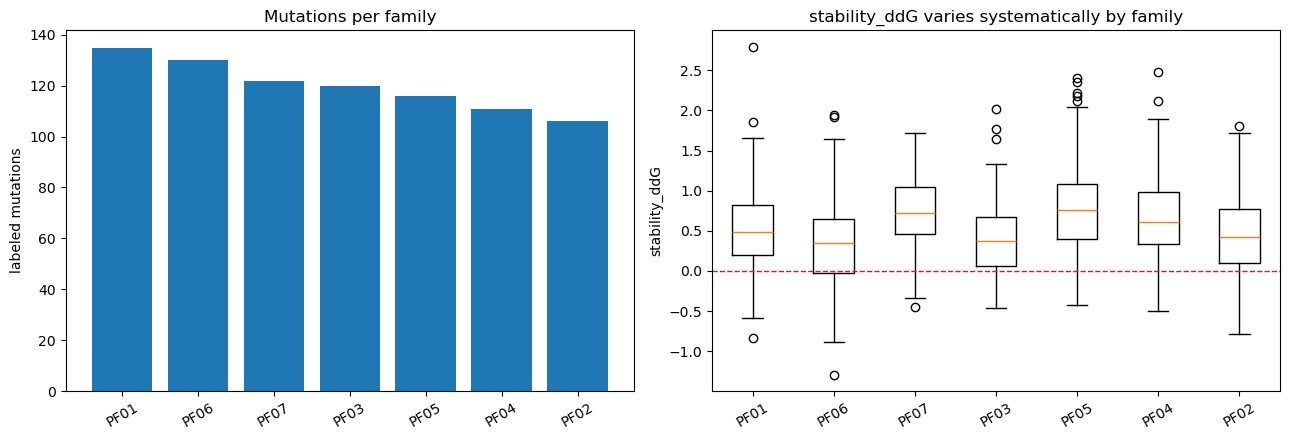

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(nesting.index, nesting["n_mutations"])
axes[0].set_ylabel("labeled mutations")
axes[0].set_title("Mutations per family")
axes[0].tick_params(axis="x", rotation=30)

families = list(nesting.index)
axes[1].boxplot([labeled_merged.loc[labeled_merged[const.COL_PROTEIN_FAMILY] == f, targets[0]]
                 .dropna() for f in families], tick_labels=families)
axes[1].axhline(0.0, color="crimson", linestyle="--", linewidth=1)
axes[1].set_ylabel(targets[0])
axes[1].set_title(f"{targets[0]} varies systematically by family")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

Because the target distribution shifts between families, family identity alone carries
real predictive signal. A random split leaks that identity across the fold boundary;
a family-grouped split does not. `src/validation.py` implements all three strategies and
`src/evaluate.py` quantifies the difference as the **optimism gap**.

## 5. What the protein embedding can and cannot do

The 256-d embedding is supplied **per protein**, so every mutation in a protein shares
one identical vector. It can therefore separate proteins, but it carries no information
at all about *which* mutation within a protein is better — which is exactly the ranking
the assignment asks for. The ablation in `src/ablation.py` confirms this empirically.

In [9]:
emb_cols = [c for c in labeled_merged.columns if c.startswith(const.EMBEDDING_PREFIX)]
within_protein_spread = (
    labeled_merged.groupby(const.COL_PROTEIN_ID)[emb_cols].std(ddof=0).to_numpy()
)
print(f"Embedding dimensions: {len(emb_cols)} (expected {const.EMBEDDING_DIM})")
print("Max within-protein standard deviation across all embedding dimensions: "
      f"{np.nanmax(within_protein_spread):.3g}")
print("=> the embedding is constant within a protein; all of its variance is between "
      "proteins.")

Embedding dimensions: 256 (expected 256)
Max within-protein standard deviation across all embedding dimensions: 0
=> the embedding is constant within a protein; all of its variance is between proteins.


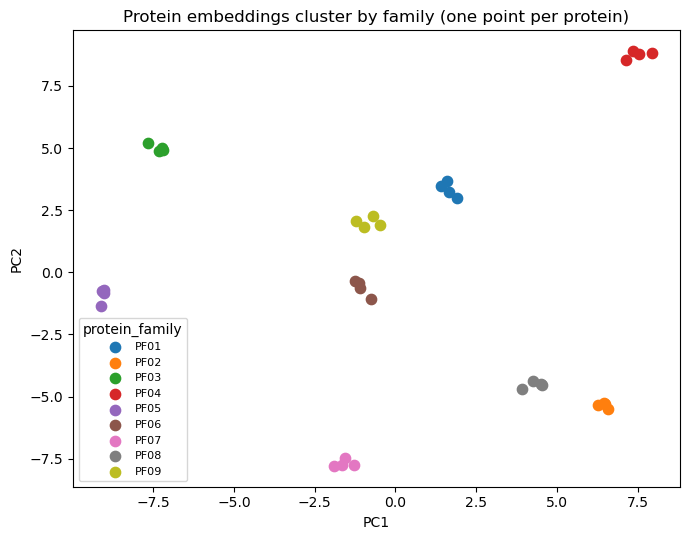

In [10]:
from sklearn.decomposition import PCA

# Illustrative only: the pipeline fits PCA *inside* each training fold, never globally.
protein_level = embeddings.set_index(const.COL_PROTEIN_ID)
components = PCA(n_components=2, random_state=cfg["project"]["random_seed"]).fit_transform(
    protein_level[emb_cols].to_numpy()
)

fig, ax = plt.subplots(figsize=(7, 5.5))
for family, group in protein_level.groupby(const.COL_PROTEIN_FAMILY):
    mask = protein_level.index.isin(group.index)
    ax.scatter(components[mask, 0], components[mask, 1], label=family, s=55)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Protein embeddings cluster by family (one point per protein)")
ax.legend(title=const.COL_PROTEIN_FAMILY, fontsize=8)
fig.tight_layout()
plt.show()

## 6. Candidates versus training data: the distribution shift

The candidates are not a random sample of the training distribution. Quantifying the
overlap here is what motivates the explicit out-of-distribution flag carried through to
the Top-10 table.

In [11]:
train_proteins = set(labeled_merged[const.COL_PROTEIN_ID])
train_families = set(labeled_merged[const.COL_PROTEIN_FAMILY])

unseen_protein = ~candidates_merged[const.COL_PROTEIN_ID].isin(train_proteins)
unseen_family = ~candidates_merged[const.COL_PROTEIN_FAMILY].isin(train_families)

overlap = pd.DataFrame(
    {
        "candidates": [len(candidates_merged)] * 2,
        "unseen": [int(unseen_protein.sum()), int(unseen_family.sum())],
    },
    index=["unseen protein", "unseen family"],
)
overlap["share"] = overlap["unseen"] / overlap["candidates"]
display(overlap)

print("Families only in the candidate pool:",
      sorted(set(candidates_merged[const.COL_PROTEIN_FAMILY]) - train_families))

,candidates,unseen,share
unseen protein,180,58,0.322222
unseen family,180,58,0.322222


Families only in the candidate pool: ['PF08', 'PF09']


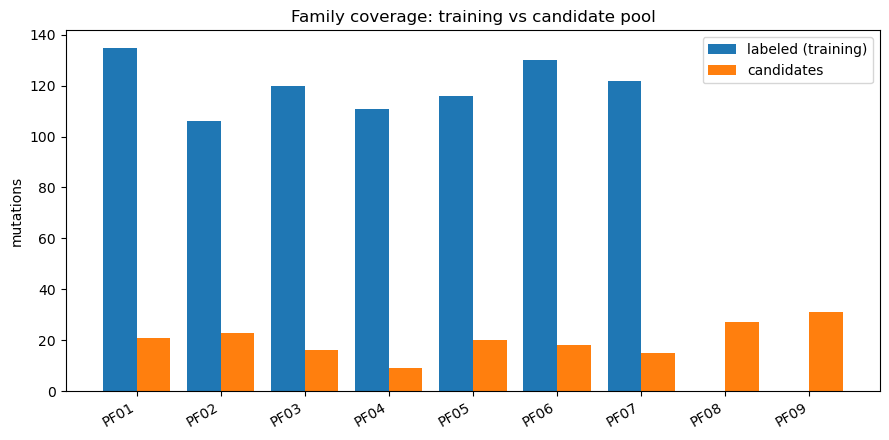

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
all_families = sorted(set(labeled_merged[const.COL_PROTEIN_FAMILY])
                      | set(candidates_merged[const.COL_PROTEIN_FAMILY]))
width = 0.4
positions = np.arange(len(all_families), dtype=float)
train_counts = [int((labeled_merged[const.COL_PROTEIN_FAMILY] == f).sum()) for f in all_families]
cand_counts = [int((candidates_merged[const.COL_PROTEIN_FAMILY] == f).sum()) for f in all_families]
ax.bar(positions - width / 2, train_counts, width=width, label="labeled (training)")
ax.bar(positions + width / 2, cand_counts, width=width, label="candidates")
ax.set_xticks(positions)
ax.set_xticklabels(all_families, rotation=30, ha="right")
ax.set_ylabel("mutations")
ax.set_title("Family coverage: training vs candidate pool")
ax.legend()
fig.tight_layout()
plt.show()

Families present only on the candidate side are precisely the rows a random-split model
would score with unearned confidence. The pipeline handles them in two ways: by selecting
models under family-grouped CV, and by carrying an explicit `ood_flag` into the final
ranking so a reviewer can see which recommendations rest on extrapolation.

---

## Where this leads

| Observation here | Enforced in |
| --- | --- |
| Mutations nest in proteins nest in families | `src/validation.py` — grouped CV |
| Family identity shifts the targets | `src/evaluate.py` — optimism gap |
| Embeddings are constant within a protein | `src/ablation.py` — feature-group arms |
| Candidates include unseen families | `src/predict.py` — OOD flag and Top-10 |

Run the full pipeline with `python main.py --config config/config.yaml`.